# Sprint 3 — The CRLB, derived properly for this BPSK model

**Sprint-3 deliverable:** a proper derivation of the Cramér–Rao lower bound for our signal model, and an overlay on the
Sprint-1 data showing where it holds and where it fails.

**What and why.** Sprint 1 *used* the formula $\text{CRLB}=1/(2\,\tfrac{E}{N_0}\,\beta^2)$. Here we derive it from first
principles, check the implementation two independent ways, and test it against the simulated MLE. Understanding
*exactly* what the CRLB assumes is what tells us *why* it fails below threshold — which motivates the ZZB (Sprint 4).

## 3.1 Derivation

**Setting.** $r[n]=\mu_n(\tau)+w[n]$ with $\mu_n(\tau)=s(t_n-\tau)$ and $w[n]\sim\mathcal N(0,\sigma^2)$ i.i.d.

**Step 1 — the score.** The log-likelihood is $\ln p(\mathbf r;\tau)=\text{const}-\frac1{2\sigma^2}\sum_n(r[n]-\mu_n(\tau))^2$,
so

$$ \frac{\partial\ln p}{\partial\tau}=\frac1{\sigma^2}\sum_n\big(r[n]-\mu_n(\tau)\big)\,\frac{\partial\mu_n}{\partial\tau}
=\frac1{\sigma^2}\sum_n w[n]\,\mu_n'(\tau). $$

Its mean is zero (because $\mathbb E\,w[n]=0$) — this is the *regularity condition* the CRLB needs.

**Step 2 — the Fisher information** is the variance of the score. Since the $w[n]$ are independent with variance
$\sigma^2$,

$$ I(\tau)=\mathbb E\Big[\Big(\frac{\partial\ln p}{\partial\tau}\Big)^2\Big]
=\frac1{\sigma^4}\sum_n\sum_m\mathbb E[w[n]w[m]]\,\mu_n'\mu_m'=\frac1{\sigma^2}\sum_n\big(\mu_n'(\tau)\big)^2 . $$

**Step 3 — plug in the delay model.** $\mu_n'(\tau)=\frac{\partial}{\partial\tau}s(t_n-\tau)=-s'(t_n-\tau)$, so

$$ I(\tau)=\frac{1}{\sigma^2}\sum_n s'(t_n-\tau)^2,\qquad
\operatorname{var}(\hat\tau)\ \ge\ \frac{\sigma^2}{\sum_n s'(t_n-\tau)^2}\quad\text{for any unbiased }\hat\tau . $$

**Step 4 — rewrite in physical terms.** Using $\sigma^2=\sum_n s[n]^2/(2E/N_0)$ (Sprint 0):

$$ \boxed{\text{CRLB}=\frac{1}{2\,(E/N_0)\,\beta^2},\qquad
\beta^2=\frac{\sum_n s'[n]^2}{\sum_n s[n]^2}=\frac{\int(2\pi f)^2|S(f)|^2\,df}{\int|S(f)|^2\,df}} $$

The second form of $\beta^2$ (the **mean-square or Gabor bandwidth**) follows from Parseval's theorem, because
differentiation multiplies the spectrum by $j2\pi f$.

**What the formula says.**
* Accuracy improves with **energy**: doubling the pilot length (or SNR) halves the CRLB. Per chip,
  $\text{CRLB}=1/(2N_c\,(E_c/N_0)\,\beta^2)$.
* Accuracy improves with **bandwidth**: steeper edges (larger $\beta^2$) mean a sharper correlation peak.
* Rectangular chips have $\beta^2=\infty$ → CRLB = 0. This is exactly why we use a band-limited pulse.
* It does **not** depend on $\tau$, as long as the whole pulse train stays inside the observation window (true here).

In [1]:
# --- setup: import the project's small core library (../sdet) -------------
import sys, inspect
sys.path.insert(0, "..")
import numpy as np
from sdet import *
from sdet.style import COLORS, INK2, MUTED, apply_style, plt
%matplotlib inline
apply_style()
FIG = "../figures/"     # figures are also saved here for slides
DATA = "../data/"       # small result files shared between notebooks

## 3.2 What the code implements
`rms_bandwidth_sq` computes $\beta^2$ from the samples ($s'$ by a central difference, error ~$10^{-10}$); `crlb` applies
the boxed formula.

In [2]:
print(inspect.getsource(rms_bandwidth_sq))
print(inspect.getsource(crlb))

def rms_bandwidth_sq(scenario):
    """beta^2 = sum s'[n]^2 / sum s[n]^2  (in 1/chip^2), the 'Gabor bandwidth'."""
    t = scenario.t - scenario.tau_c
    ds = scenario.wave.derivative(t)
    return float(np.sum(ds ** 2) / np.sum(scenario.wave(t) ** 2))

def crlb(scenario, en0):
    """Classical CRLB on the delay: var >= sigma^2 / sum s'^2 = 1 / (2 (E/N0) beta^2)."""
    return 1.0 / (2.0 * np.asarray(en0) * rms_bandwidth_sq(scenario))



## 3.3 Two independent checks of the implementation

1. **Frequency domain vs time domain.** Compute $\beta^2$ from the FFT of a finely sampled waveform (64 samples/chip)
   using the spectral formula, and compare with the discrete sum used in the code.
2. **Independence of $\tau$.** Evaluate $\beta^2$ at several delays.

In [3]:
cfg = Config()
sc = BatchScenario(cfg, np.random.default_rng(cfg.seed))
fs = 64
tt = np.arange(-cfg.span - 2, cfg.n_chips + cfg.span + 2, 1 / fs)
spec = np.abs(np.fft.rfft(sc.wave(tt), n=8 * tt.size)) ** 2
f = np.fft.rfftfreq(8 * tt.size, d=1 / fs)
beta2_fft = np.sum((2 * np.pi * f) ** 2 * spec) / np.sum(spec)
print(f"beta^2: frequency domain = {beta2_fft:.4f},  time-domain code = {rms_bandwidth_sq(sc):.4f}  (1/chip^2)")

ds = [sc.wave.derivative(sc.t - (sc.tau_c + d)) for d in (-1.7, -0.4, 0.0, 0.9, 1.6)]
vals = [np.sum(x ** 2) / sc.energy for x in ds]
print("beta^2 at five delays across the prior:", np.round(vals, 5))

beta^2: frequency domain = 2.4470,  time-domain code = 2.4481  (1/chip^2)
beta^2 at five delays across the prior: [2.44808 2.44809 2.44807 2.44809 2.44809]


## 3.4 A finding: the CRLB depends on the pilot pattern

$\beta^2$ is the bandwidth of the *actual* chip pattern, not just of the pulse: a pilot with many sign changes has more
high-frequency energy. Averaged over random pilots, $\beta^2$ is close to the pulse's own value (within ~1 %); for a single 64-chip
pilot it varies a lot. **Consequence for the project:** every estimator and bound must use the *same* pilot (which we
do), and thresholds measured relative to the CRLB will vary between pilots.

mean over 400 pilots = 2.873 (pulse 2.838); range 1.77 - 4.27


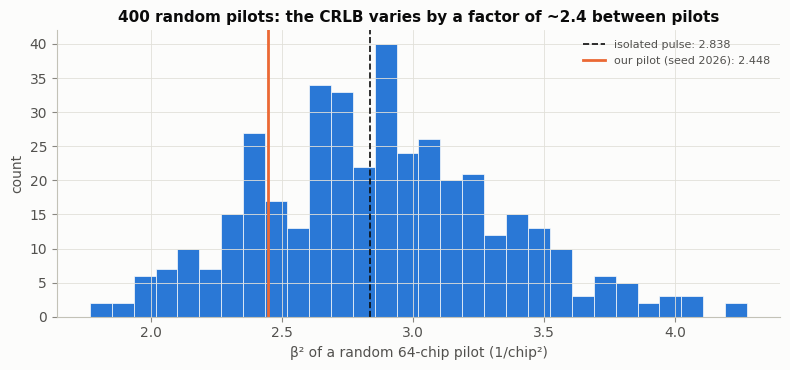

In [4]:
tp = np.linspace(-cfg.span, cfg.span, 200001)
pp = truncated_pulse(tp, cfg.rolloff, cfg.span)
beta2_pulse = np.trapezoid(np.gradient(pp, tp) ** 2, tp) / np.trapezoid(pp ** 2, tp)
b = np.array([rms_bandwidth_sq(BatchScenario(cfg, np.random.default_rng(s))) for s in range(400)])
fig, ax = plt.subplots(figsize=(8, 3.8))
ax.hist(b, bins=30, color=COLORS["mle"], edgecolor="#fcfcfb", linewidth=0.5)
ax.axvline(beta2_pulse, color=COLORS["crlb"], ls="--", lw=1.2, label=f"isolated pulse: {beta2_pulse:.3f}")
ax.axvline(rms_bandwidth_sq(sc), color=COLORS["dll"], lw=2, label=f"our pilot (seed 2026): {rms_bandwidth_sq(sc):.3f}")
ax.set_xlabel("β² of a random 64-chip pilot (1/chip²)"); ax.set_ylabel("count")
ax.set_title("400 random pilots: the CRLB varies by a factor of ~2.4 between pilots")
ax.legend(loc="upper right", fontsize=8)
fig.tight_layout(); fig.savefig(FIG + "s3_beta2_pilots.png")
print(f"mean over 400 pilots = {b.mean():.3f} (pulse {beta2_pulse:.3f}); range {b.min():.2f} - {b.max():.2f}")

## 3.5 Overlay on the Sprint-1 data

We reload the 2000-trial MLE errors from Sprint 1 and compare their MSE with the CRLB. The band is a 95 % Monte Carlo
confidence interval for MSE/CRLB (±1.96 standard errors of the mean of $e^2$).

The CRLB is a bound for **unbiased** estimators, so we also measure the bias. Averaged over the symmetric prior,
biases cancel (a delay near the right edge is pulled left, one near the left edge is pulled right), so we look at a
**fixed** delay near the edge, $\tau=\tau_c+1.5$ chips: the conditional bias $\mathbb E[\hat\tau-\tau\mid\tau]$.

conditional bias at tau = tau_c + 1.5: -10 dB: -1.175, -4 dB: -0.937, 2 dB: -0.467, 8 dB: -0.029, 14 dB: +0.003, 20 dB: +0.000, 26 dB: -0.001
High SNR (>= 14 dB): mean MSE/CRLB = 0.997  (individual points 0.96-1.03)
The CRLB exceeds the prior variance below about -8 dB: there it is meaningless (it 'allows' more error than knowing nothing).


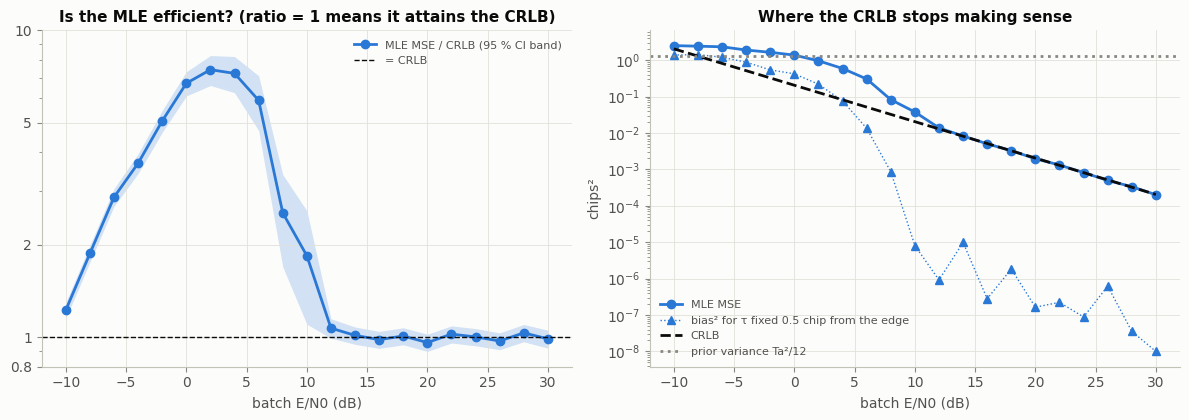

In [5]:
d = np.load(DATA + "s1_mle.npz")
snr_db, err = d["snr_db"], d["err"]
cr = crlb(sc, 10 ** (snr_db / 10))
q = err ** 2 / cr[:, None]
ratio, se = q.mean(1), q.std(1) / np.sqrt(q.shape[1])
rng = np.random.default_rng(5)
mle = BatchMLE(sc)
tau_fix = np.full(2000, sc.tau_c + 1.5)                  # fixed delay, 0.5 chip from the right edge
bias_fix = np.array([np.mean(mle.estimate(sc.observe(tau_fix, e, rng)) - tau_fix)
                     for e in 10 ** (snr_db / 10)])

fig, ax = plt.subplots(1, 2, figsize=(12, 4.3))
ax[0].fill_between(snr_db, ratio - 1.96 * se, ratio + 1.96 * se, color=COLORS["mle"], alpha=0.2, lw=0)
ax[0].semilogy(snr_db, ratio, "o-", color=COLORS["mle"], label="MLE MSE / CRLB (95 % CI band)")
ax[0].set_yticks([0.8, 1, 2, 5, 10], ["0.8", "1", "2", "5", "10"])
ax[0].axhline(1, color=COLORS["crlb"], ls="--", lw=1, label="= CRLB")
ax[0].set_xlabel("batch E/N0 (dB)"); ax[0].set_title("Is the MLE efficient? (ratio = 1 means it attains the CRLB)")
ax[0].legend(loc="upper right", fontsize=8)

mse = np.mean(err ** 2, 1)
ax[1].semilogy(snr_db, mse, "o-", color=COLORS["mle"], label="MLE MSE")
ax[1].semilogy(snr_db, np.maximum(bias_fix ** 2, 1e-8), "^:", color=COLORS["mle"], lw=1,
               label="bias² for τ fixed 0.5 chip from the edge")
ax[1].semilogy(snr_db, cr, color=COLORS["crlb"], ls="--", label="CRLB")
ax[1].axhline(prior_variance(cfg), color=COLORS["prior"], ls=":", label="prior variance Ta²/12")
ax[1].set_xlabel("batch E/N0 (dB)"); ax[1].set_ylabel("chips²")
ax[1].set_title("Where the CRLB stops making sense"); ax[1].legend(loc="lower left", fontsize=8)
fig.tight_layout(); fig.savefig(FIG + "s3_crlb_vs_mle.png")

hi = snr_db >= 14
print("conditional bias at tau = tau_c + 1.5:", ", ".join(f"{d:.0f} dB: {b:+.3f}" for d, b in
      zip(snr_db[::3], bias_fix[::3])))
print(f"High SNR (>= 14 dB): mean MSE/CRLB = {ratio[hi].mean():.3f}  (individual points {ratio[hi].min():.2f}-{ratio[hi].max():.2f})")
cross = snr_db[np.argmax(cr < prior_variance(cfg))]
print(f"The CRLB exceeds the prior variance below about {cross:.0f} dB: there it is meaningless (it 'allows' "
      f"more error than knowing nothing).")

### One more subtlety: the edges of the prior window
The MLE is *constrained* to the prior window. For a delay right at the edge, half of its possible errors are cut off,
so it can beat the (unconstrained) CRLB there. We check how large this is.

In [6]:
rng = np.random.default_rng(5)
mle = BatchMLE(sc)
e20 = 10 ** 2.0
for name, lo, hi_ in (("centre of window ", -0.5, 0.5), ("within 0.05 of edge", 1.95, 2.0)):
    tau = sc.tau_c + rng.uniform(lo, hi_, 4000)
    e = mle.estimate(sc.observe(tau, e20, rng)) - tau
    print(f"tau near {name}: MSE/CRLB at 20 dB = {np.mean(e**2) / crlb(sc, e20):.2f}")
print("(overall effect on the averaged MSE: about 1 %, because few delays are that close to an edge)")

tau near centre of window : MSE/CRLB at 20 dB = 1.00


tau near within 0.05 of edge: MSE/CRLB at 20 dB = 0.63
(overall effect on the averaged MSE: about 1 %, because few delays are that close to an edge)


## 3.6 Results and what they mean

* **The derivation and the code agree.** $\beta^2$ from the spectrum and from the samples match to 0.05 %, and it does
  not depend on $\tau$ — exactly as the derivation predicts.
* **The MLE attains the CRLB at high SNR.** Above ≈ 14 dB the ratio MSE/CRLB is 1 within the Monte Carlo band. This is
  the classical asymptotic efficiency of the MLE, now confirmed for this specific signal. (Points slightly below 1 are
  sampling noise plus the small edge effect shown above.)
* **The CRLB fails below threshold — for three identifiable reasons:**
  1. *It assumes an unbiased estimator.* Below threshold the MLE is clearly biased for a given delay (towards the
     window centre when the delay is near an edge — bias² curve), so the bound no longer applies to it.
  2. *It is local.* $I(\tau)$ only involves $s'$ at the true delay, i.e. the curvature of the true correlation peak.
     It cannot know that other peaks exist (Sprint 1, §1.4).
  3. *It ignores the prior.* At low SNR it exceeds $T_a^2/12$ — it would allow more error than guessing the centre of
     the window, which is absurd for a bound.
* **The CRLB is pilot-specific** (factor ≈ 2.4 between random pilots), which is why one pilot is used throughout.

**Why this is needed for the next sprint.** Reasons 2 and 3 say what a better bound must do: account for *distant*
competing delays and for the *prior*. The Ziv–Zakai bound does both — Sprint 4.